# Geometry of Forgetting — live overview (v3)

**What this notebook is.** A walk through the project in which every number and every figure is
computed by the cells below, from the repository code, at run time. Nothing is loaded from
`results/`. Running it top to bottom reproduces everything shown.

## 0. Rules this notebook follows

1. **Computed here.** No file under `results/` is read. Long computations write a cache to
   `notebooks/_v3_cache/`. Each cache entry is keyed by the full configuration *and* a hash of
   every file under `src/` plus `notebooks/v3_lib.py`, so a cached result is reused only if the
   code that produced it is byte-identical to the code now on disk. Delete the folder to
   recompute from scratch.
2. **No pooling across stream conditions.** Every figure is faceted by condition. The only
   averaging is over independent replicates of the same condition, always shown with a 95%
   confidence interval (`t_{0.975,n−1}·SEM`).
3. **Conditions are named by their parameters.** A condition is `(s_f, Hamming)`. Words that
   describe an outcome are not used to name a condition.
4. **Observations, not conclusions.** Only consecutive-task similarity is varied here. Task
   order is fixed (generated order, one pass) and is the subject of a separate, later notebook.
   Statements about what a pattern *means* wait for the final evaluation across similarity,
   order, and scale.
5. **Reduced scale.** This is a robustness configuration (`M = 50` points per manifold instead
   of 150, GLUE `n_t = 50` instead of 200). It is not the paper configuration, so its numbers are
   not comparable to earlier campaigns. Because `M` changed, the learning rate is re-pinned here
   (§3) rather than inherited.


In [1]:
import os, sys, time, json
from pathlib import Path

# Before NumPy. OpenBLAS latches the thread count at load; see v3_lib.py.
for _blas_threads in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_blas_threads] = "1"

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]
os.chdir(ROOT)
os.environ.setdefault("PYTHONUTF8", "1")

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import v3_lib as v
from src import provenance

WORKERS = max(1, (os.cpu_count() or 2) - 1)
PROJ_DIM = 3          # 3-D point-cloud plots; set to 2 for flat projections

# GOF_V3_SMOKE=1 runs every cell end to end on a tiny configuration to catch code errors.
# Its numbers mean nothing and it uses its own cache.
SMOKE = os.environ.get("GOF_V3_SMOKE") == "1"
CACHE = ROOT / "notebooks" / ("_v3_cache_smoke" if SMOKE else "_v3_cache")
CACHE.mkdir(exist_ok=True)
cfg0 = v.V3Config(T=4, M=10, n_t=6, steps_per_task=4000) if SMOKE else v.V3Config()
if SMOKE:
    print("*** SMOKE CONFIGURATION — numbers are meaningless ***")
print("git SHA:", provenance.git_sha(), "| working tree dirty:", provenance.git_dirty())
print("code digest (src/ + v3_lib.py):", v.CODE_DIGEST)
print("workers:", WORKERS)
print(cfg0)
GAMMA_COLORS = dict(zip(v.GAMMAS, plt.cm.viridis(np.linspace(0.0, 0.9, len(v.GAMMAS)))))
LABEL_COLOR = {1: "tab:red", -1: "tab:blue"}


git SHA: 2cb10d1 | working tree dirty: True
code digest (src/ + v3_lib.py): 3d95619d3b1b3f7d
workers: 11
V3Config(T=16, P=16, d=150, M=50, D=4, R=1.0, N=300, n_t=50, lr0=5.0, target_loss=0.05, steps_per_task=20000, record_every=200, geometry_module='A')


## 1. The objects

**One task** is a set of `P` point clouds ("manifolds") in an input space of dimension `d`, plus
a **dichotomy**: a label `+1` or `−1` for each whole cloud. The network must map every point of a
cloud to that cloud's label. Labels are always balanced (`P/2` of each sign).

Each cloud has a centre and `M` points sampled on a `D`-dimensional sphere of radius `R` around
that centre, plus small isotropic noise.

| symbol | meaning | here (reduced) | design point |
|---|---|---|---|
| `P` | clouds per task | 16 | 16 |
| `M` | points per cloud | **50** | 150 |
| `d` | input dimension | 150 | 150 |
| `D` | intrinsic dimension of each cloud | 4 | 4 |
| `R` | radius of each cloud | 1 | 1 |
| `N` | hidden units per module (two modules) | 300 | 300 |
| `T` | tasks per stream | 16 | 16 |
| `n_t` | GLUE Monte-Carlo samples | **50** | 200 |

The plot below is task 0 of the stream that replicate 0 is trained on. The 150-dimensional
points are projected onto their top principal axes, and the panel title states how much variance
that projection keeps. A projection can hide separation that exists in 150 dimensions, so the
plot shows *what the data are*, not how separable they are. Separability is measured below.


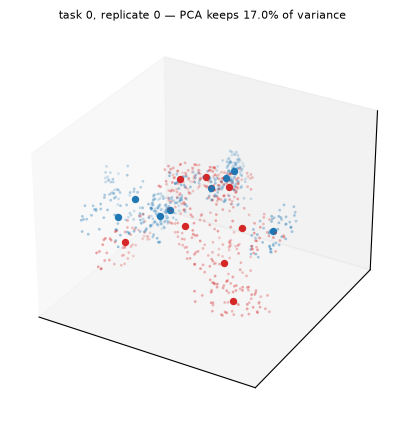

labels y_0 = [1, -1, 1, 1, 1, 1, -1, -1, -1, 1, -1, -1, -1, -1, 1, 1]


In [2]:
def project(points, basis):
    mu, V, _ = basis
    return (np.asarray(points) - mu) @ V.T


def new_axes(fig, nrows, ncols, idx):
    if PROJ_DIM == 3:
        return fig.add_subplot(nrows, ncols, idx, projection="3d")
    return fig.add_subplot(nrows, ncols, idx)


def draw_task(ax, points, centers, y, basis, *, flipped=None, title="", s=2):
    Z, C = project(points, basis), project(centers, basis)
    for i in range(Z.shape[0]):
        col = LABEL_COLOR[int(y[i])]
        ax.scatter(*Z[i, :, :PROJ_DIM].T, s=s, color=col, alpha=0.65, linewidths=0)
        edge = "black" if (flipped is not None and flipped[i]) else col
        ax.scatter(*C[i, :PROJ_DIM], s=28, color=col, edgecolors=edge,
                   linewidths=1.6 if edge == "black" else 0.0)
    ax.set_title(title, fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    if PROJ_DIM == 3:
        ax.set_zticks([])


stream0 = v.build_stream(cfg0, 1.0, 0, v.EVAL_STREAM_BASE + 0)
A0, y0 = stream0.arrangements[0], stream0.dichotomies[0]
basis0 = v.pca_basis(A0.points.reshape(-1, cfg0.d), k=3)
fig = plt.figure(figsize=(5.5, 5))
ax = new_axes(fig, 1, 1, 1)
draw_task(ax, A0.points, A0.centers, y0, basis0, s=4,
          title=f"task 0, replicate 0 — PCA keeps {100*basis0[2][:PROJ_DIM].sum():.1f}% of variance")
plt.show()
print("labels y_0 =", y0.tolist())


**Capacity, measured on these clouds.** Manifold capacity `α = P / N_crit`. Here `N_crit` is the
smallest number of random linear measurements of the input in which a random balanced dichotomy
of the clouds is still linearly separable, cloud by cloud. Larger `α` means the clouds are easier
to separate. GLUE estimates `α` from the clouds' *anchor points*, the points that bind the
max-margin separator, and reports three factors (§4).

There are two ensembles of dichotomies:
- **generic**: averaged over random balanced dichotomies.
- **retained**: one fixed dichotomy, here the task's own labels `y_0`.

The next cell measures both on the raw input clouds of task 0.


In [3]:
g_in = v.manifold_geometry(v.input_manifolds(A0.points), None, n_t=cfg0.n_t, seed=1)
r_in = v.manifold_geometry(v.input_manifolds(A0.points), y0, n_t=cfg0.n_t, seed=2)
for name, g in (("generic", g_in), ("retained (y_0)", r_in)):
    print(f"{name:15s} alpha={g['alpha']:.3f}  Psi_eff={g['Psi_eff']:.3f}  R_eff={g['R_eff']:.3f}  "
          f"D_eff={g['D_eff']:.3f}  identity residual={g['identity_residual']:.1e}")


generic         alpha=0.446  Psi_eff=0.652  R_eff=0.978  D_eff=2.990  identity residual=1.2e-16
retained (y_0)  alpha=0.435  Psi_eff=0.729  R_eff=1.082  D_eff=3.110  identity residual=1.3e-16


## 2. The streams that are trained

A stream is `T = 16` tasks. Each task is built from the previous one by two independent knobs.
Both are verified against `src/manifolds/streams.py` and `generator.py`:

- **Feature similarity `s_f`** moves the clouds. Each centre becomes
  `c_t = s_f · c_{t−1} + √(1 − s_f²) · z`, with `z` a fresh Gaussian vector rescaled to the
  previous centres' size. Each cloud keeps its axes and intrinsic coordinates. Its points are
  **always re-sampled** with fresh noise, including at `s_f = 1`.
  - `s_f = 1`: centres copied exactly. New points, same clouds.
  - `s_f = 0.9`: centres mostly kept.
  - `s_f = 0.1`: centres almost entirely redrawn.
- **Hamming distance** changes the rule. `y_t` is `y_{t−1}` with exactly `h` labels flipped,
  keeping balance. In readout-similarity units `s_r = 1 − 2h/P`.
  - `h = 0`: same labels every task.
  - `h = 8`: half the labels flipped, `s_r = 0`, orthogonal rule.
  - The earlier registered "corners" used nominal `s_r = 0.9 / 0.1`. At `P = 16` these are
    Hamming 0 and Hamming 8.

**Conditions here:** `s_f ∈ {1, 0.9, 0.1}` × Hamming `∈ {0, 2, 4, 6, 8}`, 15 cells. The earlier
2×2 grid is the four cells `s_f ∈ {0.9, 0.1}` × Hamming `∈ {0, 8}`. The earlier Hamming slice is
`s_f ∈ {1, 0.9, 0.1}` × Hamming `∈ {0, 2, 4, 6}`.

**What is not varied:** order. Every stream is trained in generated order, once. Only
*consecutive* similarity is controlled. Similarity to tasks further back is whatever the chain
produces, and it is measured below rather than assumed.

**Pairing.** Within one replicate, task 0 (its clouds *and* its labels) is identical in all 15
cells. The next cell asserts it. The cells therefore differ only in what happens after task 0.


In [3]:
CELLS = v.all_cells()
streams_r0 = {c: v.build_stream(cfg0, c[0], c[1], v.EVAL_STREAM_BASE + 0) for c in CELLS}
ref = streams_r0[CELLS[0]]
for c, s in streams_r0.items():
    assert np.array_equal(s.arrangements[0].points, ref.arrangements[0].points), c
    assert np.array_equal(s.dichotomies[0], ref.dichotomies[0]), c
print("task 0 identical across all", len(CELLS), "cells of replicate 0")


task 0 identical across all 15 cells of replicate 0


### 2.1 Every task of every stream (replicate 0)

One figure per condition. Each figure shows all 16 tasks in a single principal-component basis,
fitted on all points of that one stream, so movement between panels is real movement in that
basis. Each basis belongs to its own stream; figures are never put into a shared basis.
- **Colour** shows the label (red `+1`, blue `−1`).
- **Black-ringed centres** are clouds whose label flipped relative to the previous task.
- **Panel titles** give the Hamming distance to task 0 and the measured mean centre cosine to
  task 0.


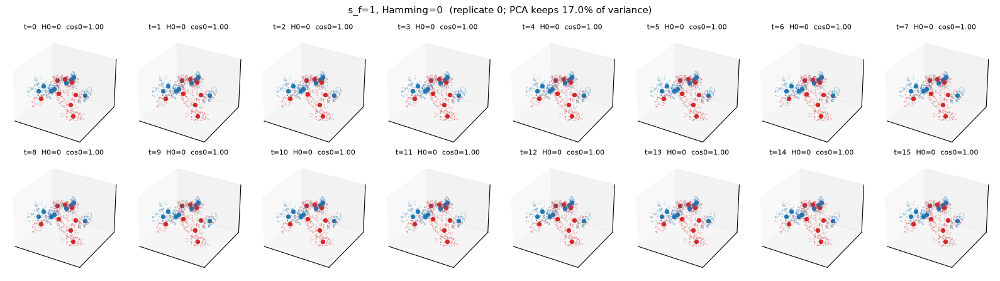

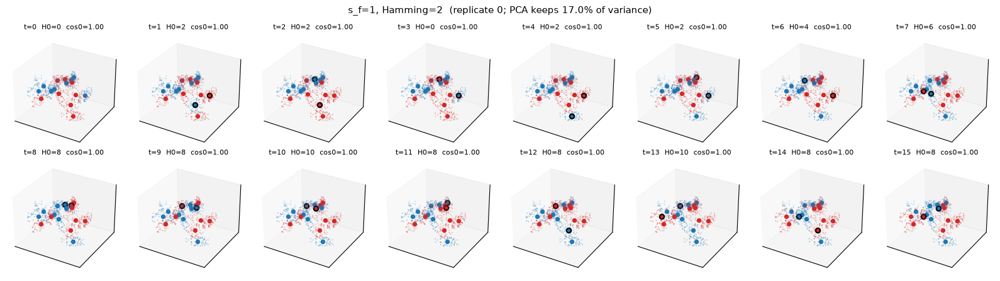

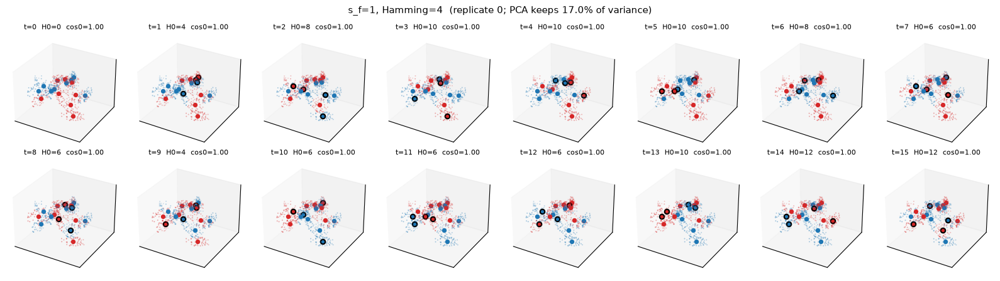

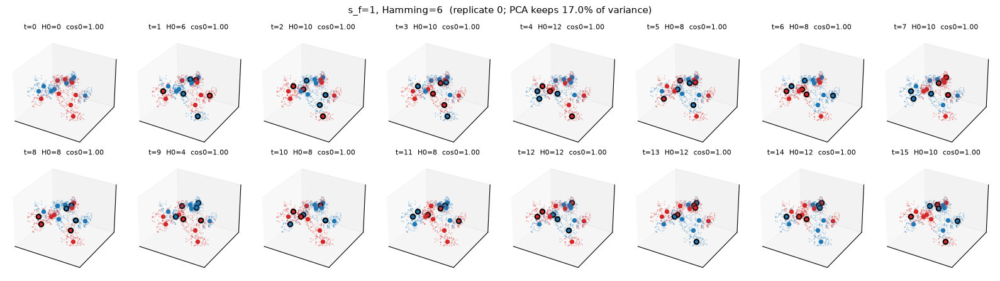

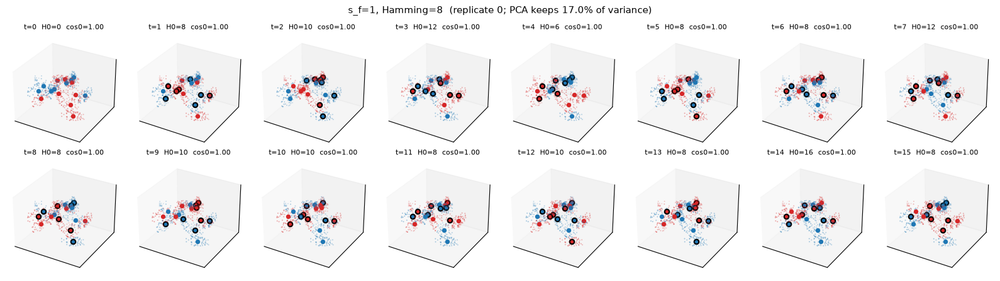

...

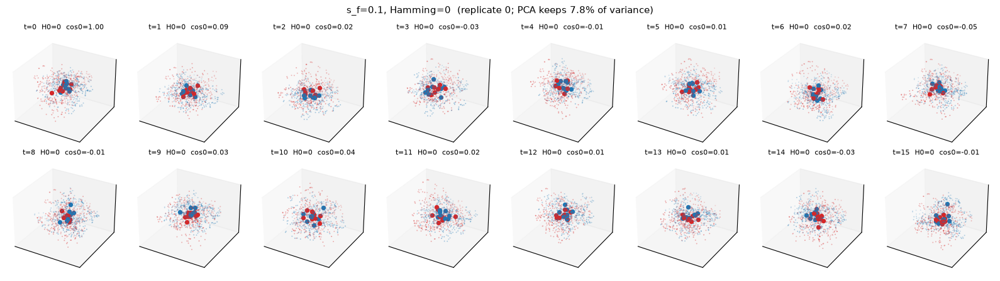

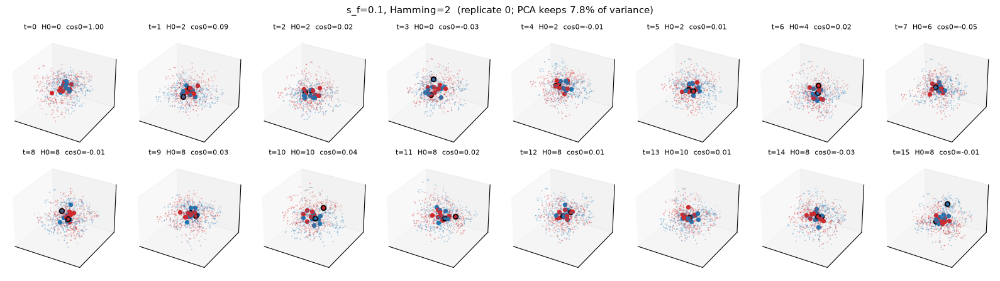

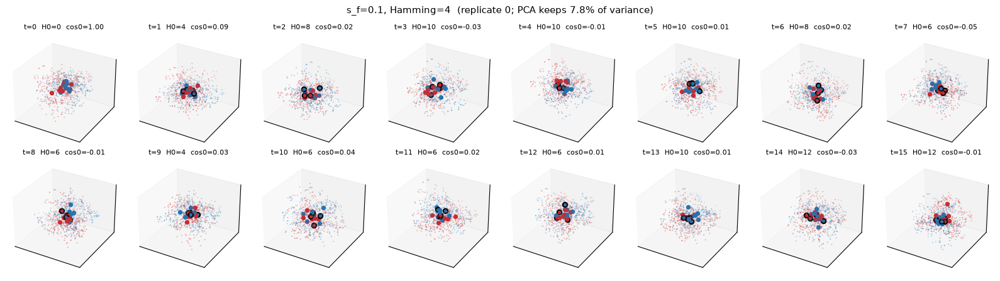

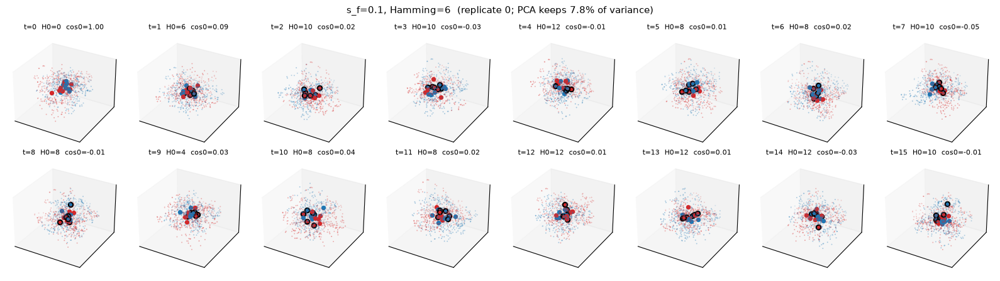

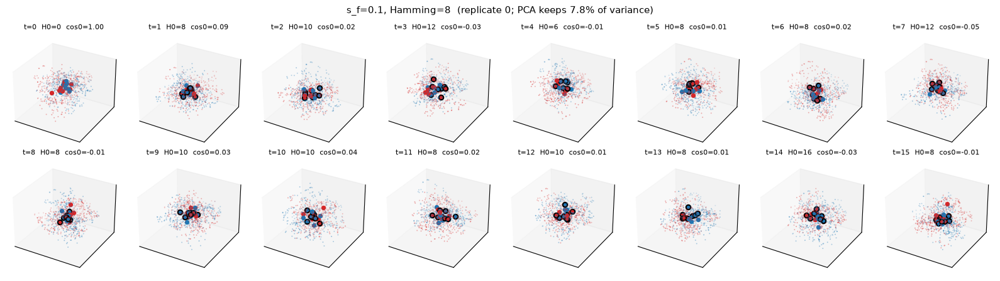

In [4]:
def stream_figure(stream, label):
    T = len(stream.arrangements)
    X = np.concatenate([a.points.reshape(-1, cfg0.d) for a in stream.arrangements])
    basis = v.pca_basis(X, k=3)
    cos = v.centre_cosine_matrix(stream)
    ncols = min(8, T); nrows = -(-T // ncols)
    fig = plt.figure(figsize=(16, 2.3 * nrows))
    for t in range(T):
        ax = new_axes(fig, nrows, ncols, t + 1)
        y = stream.dichotomies[t]
        flipped = None if t == 0 else (y != stream.dichotomies[t - 1])
        ham0 = int(np.sum(y != stream.dichotomies[0]))
        draw_task(ax, stream.arrangements[t].points, stream.arrangements[t].centers, y, basis,
                  flipped=flipped, title=f"t={t}  H0={ham0}  cos0={cos[0, t]:.2f}")
    fig.suptitle(f"{label}  (replicate 0; PCA keeps {100*basis[2][:PROJ_DIM].sum():.1f}% of variance)",
                 fontsize=11)
    plt.tight_layout()
    plt.show()


for c in CELLS:
    stream_figure(streams_r0[c], v.cell_label(*c))


### 2.2 Similarity between all pairs of tasks (replicate 0)

The left block shows the **measured** mean cosine between corresponding centres of tasks `i`
and `j`. The stored `S_f` puts the nominal `s_f` on the first off-diagonal; this matrix is
computed from the centres themselves. The right block shows the readout similarity
`s_r(y_i, y_j) = |⟨y_i, y_j⟩|/P`. It is sign-symmetric, so a fully flipped rule counts as the
same rule.


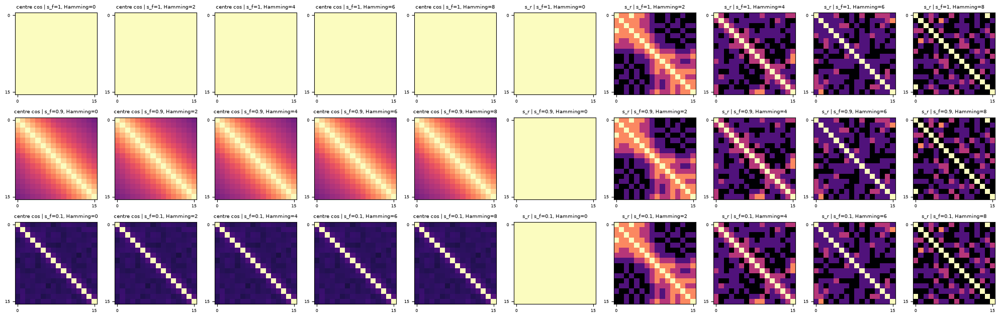

In [6]:
fig, axes = plt.subplots(3, 10, figsize=(20, 6.4))
for i, s_f in enumerate(v.S_F_LEVELS):
    for j, h in enumerate(v.HAMMING_LEVELS):
        s = streams_r0[(s_f, h)]
        a1, a2 = axes[i, j], axes[i, 5 + j]
        a1.imshow(v.centre_cosine_matrix(s), vmin=-0.2, vmax=1, cmap="magma")
        a2.imshow(s.S_r, vmin=0, vmax=1, cmap="magma")
        a1.set_title(f"centre cos | {v.cell_label(s_f, h)}", fontsize=7)
        a2.set_title(f"s_r | {v.cell_label(s_f, h)}", fontsize=7)
        for a in (a1, a2):
            a.set_xticks([0, 15]); a.set_yticks([0, 15]); a.tick_params(labelsize=6)
plt.tight_layout(); plt.show()


### 2.3 The same statistics over replicates

The table checks that the realized streams match their parameters across many replicates, not
just replicate 0. Columns:
- the measured consecutive centre cosine (mean ± sd over all task pairs and replicates);
- the centre cosine and the Hamming distance between task 0 and task 12, i.e. 12 tasks later;
- `s_r` between task 0 and task 12.

Twelve tasks later is shown only because earlier campaigns read at that lag. The trajectories
below cover every lag.


In [7]:
N_STREAM_CHECK = 2 if SMOKE else 8
LAG_READ = min(12, cfg0.T - 1)
rows = ["| s_f | Hamming | consecutive centre cos | cos(task 0, task L) | Hamming(task 0, task L) | s_r(task 0, task L) |",
        "|---|---|---|---|---|---|"]
for s_f, h in CELLS:
    cons, c12, h12, r12 = [], [], [], []
    for r in range(N_STREAM_CHECK):
        s = v.build_stream(cfg0, s_f, h, v.EVAL_STREAM_BASE + r)
        C = v.centre_cosine_matrix(s)
        cons += [C[t, t + 1] for t in range(cfg0.T - 1)]
        c12.append(C[0, LAG_READ]); r12.append(s.S_r[0, LAG_READ])
        h12.append(int(np.sum(s.dichotomies[0] != s.dichotomies[LAG_READ])))
    rows.append(f"| {s_f:g} | {h} | {np.mean(cons):.3f} ± {np.std(cons):.3f} | "
                f"{np.mean(c12):.3f} ± {np.std(c12):.3f} | {np.mean(h12):.1f} (range {min(h12)}–{max(h12)}) | "
                f"{np.mean(r12):.2f} ± {np.std(r12):.2f} |")
display(Markdown(f"L = {LAG_READ}\n\n" + "\n".join(rows)))


L = 12

| s_f | Hamming | consecutive centre cos | cos(task 0, task L) | Hamming(task 0, task L) | s_r(task 0, task L) |
|---|---|---|---|---|---|
| 1 | 0 | 1.000 ± 0.000 | 1.000 ± 0.000 | 0.0 (range 0–0) | 1.00 ± 0.00 |
| 1 | 2 | 1.000 ± 0.000 | 1.000 ± 0.000 | 7.5 (range 4–10) | 0.19 ± 0.17 |
| 1 | 4 | 1.000 ± 0.000 | 1.000 ± 0.000 | 8.8 (range 6–12) | 0.22 ± 0.20 |
| 1 | 6 | 1.000 ± 0.000 | 1.000 ± 0.000 | 9.5 (range 8–12) | 0.19 ± 0.21 |
| 1 | 8 | 1.000 ± 0.000 | 1.000 ± 0.000 | 9.2 (range 8–12) | 0.16 ± 0.17 |
| 0.9 | 0 | 0.900 ± 0.002 | 0.293 ± 0.021 | 0.0 (range 0–0) | 1.00 ± 0.00 |
| 0.9 | 2 | 0.900 ± 0.002 | 0.293 ± 0.021 | 7.5 (range 4–10) | 0.19 ± 0.17 |
| 0.9 | 4 | 0.900 ± 0.002 | 0.293 ± 0.021 | 8.8 (range 6–12) | 0.22 ± 0.20 |
| 0.9 | 6 | 0.900 ± 0.002 | 0.293 ± 0.021 | 9.5 (range 8–12) | 0.19 ± 0.21 |
| 0.9 | 8 | 0.900 ± 0.002 | 0.293 ± 0.021 | 9.2 (range 8–12) | 0.16 ± 0.17 |
| 0.1 | 0 | 0.101 ± 0.021 | -0.009 ± 0.019 | 0.0 (range 0–0) | 1.00 ± 0.00 |
| 0.1 | 2 | 0.101 ± 0.021 | -0.009 ± 0.019 | 7.5 (range 4–10) | 0.19 ± 0.17 |
| 0.1 | 4 | 0.101 ± 0.021 | -0.009 ± 0.019 | 8.8 (range 6–12) | 0.22 ± 0.20 |
| 0.1 | 6 | 0.101 ± 0.021 | -0.009 ± 0.019 | 9.5 (range 8–12) | 0.19 ± 0.21 |
| 0.1 | 8 | 0.101 ± 0.021 | -0.009 ± 0.019 | 9.2 (range 8–12) | 0.16 ± 0.17 |

## 3. Training operating point, set here

**Network.** Two modules of `N` ReLU units each see the same input. Their outputs are summed by
one shared linear readout, which starts at zero, so the network outputs 0 for every input at
initialization. Training is plain full-batch gradient descent on squared error to the `±1`
labels, with no weight decay, no normalization, and no clipping. Each task trains until its loss
reaches `target_loss`, capped at 20,000 steps.

**Richness `γ`.** `γ` controls how much the hidden weights move during training, under the μP
parameterization. The learning rate is `η = lr0 · γ² · (N / 64)`. The six registered values are
`γ ∈ {0.03, 0.1, 0.3, 1, 3, 10}`. Hidden weights at initialization are bitwise identical across
`γ` for a given seed.

**Why re-check.** `lr0 = 5` and `target_loss = 0.05` were pinned at `M = 150`. The repo records
that any change of `M`, `P`, or `N` invalidates them, so they are re-checked here. The rule
follows Phase 0 practice: keep the inherited value unless it fails. It is fixed in code
(`v3_lib.calibrate`):
- Use a reserved calibration stream that is never evaluated: `s_f = 0.1`, Hamming 8, its first
  4 tasks, all six `γ`.
- Keep `lr0 = 5` if every `γ` reaches `target_loss` on every task within a quarter of the step
  cap, *and* `lr0 = 50` also reaches the target at every `γ` (stability one decade up).
- Otherwise the notebook stops. Choosing a different `lr0` is a human decision, not an automatic
  fallback.
- One value for all cells and all `γ`.

A learning-rate sweep across the final results is planned separately; this check only
establishes that the inherited value is a valid operating point at this scale.

First, check that `target_loss = 0.05` is reachable at all. The exact least-squares readout at
the initial weights gives the lowest loss a readout alone can attain.


In [8]:
cal_stream = v.build_stream(cfg0, 0.1, 8, v.CALIBRATION_STREAM_ID)
floor_ls = v.readout_floor(cfg0, cal_stream, 0)
print(f"least-squares readout loss at W(0): {floor_ls:.2e}   (target_loss = {cfg0.target_loss})")
assert floor_ls < cfg0.target_loss / 10, "target_loss is not clearly above the readout floor — stop and re-specify"


least-squares readout loss at W(0): 7.98e-05   (target_loss = 0.05)


In [9]:
t0 = time.time()
cal = v.calibrate(cfg0, workers=WORKERS, checkpoint=str(CACHE / "calibration.jsonl"))
print(f"calibration wall time this run: {time.time() - t0:.0f} s (cached jobs cost 0)")
rows = ["| lr0 | γ | reached all tasks | steps per task | final loss per task |", "|---|---|---|---|---|"]
for r in sorted(cal["results"], key=lambda r: (r["lr0"], r["gamma"])):
    rows.append(f"| {r['lr0']:g} | {r['gamma']:g} | {r['all_converged']} | "
                f"{[t['steps'] for t in r['tasks']]} | {[round(t['final_loss'], 4) for t in r['tasks']]} |")
display(Markdown("\n".join(rows)))
print(f"lr0={cal['inherited']:g} reaches at every γ: {cal['reaches']}; "
      f"every task within {cal['max_steps_allowed']:.0f} steps: {cal['margin_ok']}; "
      f"lr0={10*cal['inherited']:g} reaches at every γ: {cal['stable_decade_up']}")
print("pin:", cal["pin"])
if SMOKE and cal["pin"] is None:
    cal["pin"] = cal["inherited"]
assert cal["pin"] is not None, "the inherited lr0 fails the rule — stop; choosing another lr0 is a human decision"
cfg = v.with_pin(cfg0, cal["pin"])
print(cfg)


calibration wall time this run: 0 s (cached jobs cost 0)


| lr0 | γ | reached all tasks | steps per task | final loss per task |
|---|---|---|---|---|
| 5 | 0.03 | True | [1471, 1307, 1722, 1304] | [0.05, 0.05, 0.05, 0.05] |
| 5 | 0.1 | True | [1204, 991, 1130, 808] | [0.0499, 0.0499, 0.0499, 0.05] |
| 5 | 0.3 | True | [695, 494, 483, 330] | [0.05, 0.0498, 0.0498, 0.0498] |
| 5 | 1 | True | [292, 173, 156, 104] | [0.0497, 0.0497, 0.0497, 0.05] |
| 5 | 3 | True | [121, 63, 55, 36] | [0.0499, 0.0484, 0.0491, 0.0494] |
| 5 | 10 | True | [45, 21, 19, 12] | [0.0495, 0.0499, 0.0463, 0.0478] |
| 50 | 0.03 | True | [148, 132, 173, 131] | [0.0498, 0.0495, 0.0499, 0.0499] |
| 50 | 0.1 | True | [121, 100, 114, 82] | [0.0499, 0.0496, 0.0495, 0.0493] |
| 50 | 0.3 | True | [71, 50, 49, 34] | [0.0488, 0.0493, 0.0491, 0.0483] |
| 50 | 1 | True | [31, 18, 16, 11] | [0.0457, 0.0474, 0.0493, 0.0483] |
| 50 | 3 | True | [14, 7, 6, 5] | [0.0404, 0.0446, 0.0496, 0.0354] |
| 50 | 10 | True | [7, 3, 3, 3] | [0.0248, 0.048, 0.0485, 0.037] |

lr0=5 reaches at every γ: True; every task within 5000 steps: True; lr0=50 reaches at every γ: True
pin: 5.0
V3Config(T=16, P=16, d=150, M=50, D=4, R=1.0, N=300, n_t=50, lr0=5.0, target_loss=0.05, steps_per_task=20000, record_every=200, geometry_module='A')


### 3.1 One measured arm per `γ`, before the grid

The repository rule is: any run projected over about 30 minutes gets a measured arm first, and
contention between parallel workers is what projections get wrong. The next cell runs one full
arm per `γ` (16 tasks, all measurements) in parallel, in the costliest condition: `s_f = 0.1`,
Hamming 8, replicate 0. It reports each arm's wall time under that contention. These arms are
part of the grid and are not run twice.


In [10]:
timing_specs = [v.ArmSpec(g, 0.1, 8, 0) for g in v.GAMMAS]
t0 = time.time()
timing_arms = v.run_grid(cfg, timing_specs, workers=len(timing_specs),
                         checkpoint=str(CACHE / "grid.jsonl"))
print(f"wall time this cell: {time.time() - t0:.0f} s")
for a in timing_arms:
    steps = sum(r.get("steps", 0) for r in a["rows"])
    print(f"gamma={a['spec']['gamma']:<5g} arm wall={a['wall_seconds']:7.0f} s  total steps={steps:6d}  usable={a['usable']}")
per_rep = sum(a["wall_seconds"] for a in timing_arms) * len(CELLS)
for n in (3, 5, 8):
    print(f"projection, {n} replicates: {per_rep * n / WORKERS / 3600:.1f} h on {WORKERS} workers "
          "(upper-cost cell used for every cell; contention at full width is higher than at 6 workers)")


wall time this cell: 0 s
gamma=0.03  arm wall=   1350 s  total steps= 28906  usable=True
gamma=0.1   arm wall=    739 s  total steps= 15559  usable=True
gamma=0.3   arm wall=    456 s  total steps=  6114  usable=True
gamma=1     arm wall=    237 s  total steps=  1965  usable=True
gamma=3     arm wall=    155 s  total steps=   707  usable=True
gamma=10    arm wall=    127 s  total steps=   246  usable=True
projection, 3 replicates: 3.5 h on 11 workers (upper-cost cell used for every cell; contention at full width is higher than at 6 workers)
projection, 5 replicates: 5.8 h on 11 workers (upper-cost cell used for every cell; contention at full width is higher than at 6 workers)
projection, 8 replicates: 9.3 h on 11 workers (upper-cost cell used for every cell; contention at full width is higher than at 6 workers)


## 4. The three-factor identity, on real clouds

GLUE decomposes capacity exactly as

$$\alpha = \Psi_{\rm eff}\,\frac{1 + R_{\rm eff}^{-2}}{D_{\rm eff}}
\qquad\Longleftrightarrow\qquad
\log\alpha = \underbrace{\log\Psi_{\rm eff}}_{\text{utility}}
 + \underbrace{\log(1+R_{\rm eff}^{-2})}_{\text{radius}}
 \;\underbrace{-\,\log D_{\rm eff}}_{\text{dimension}} .$$

- `R_eff` and `D_eff` are the effective radius and dimension of the clouds' **anchor points**.
- `Ψ_eff` (effective utility) is a correction factor for how the anchors are used. It is not the
  pairwise centre–axis alignment ψ.
- The identity is exact. Its residual is printed with every measurement.

**`R_eff` and `D_eff` are not the generator's `R` and `D`.** For single points (`R = 0`, `D = 0`)
the next cell measures `R_eff ≈ 1` and `D_eff ≈ 1`, while `α` approaches 2, the exact capacity
of points.
- That measurement is a fact.
- The likely mechanism is *inferred*, from the `center_policy="all"` convention in
  `src/glue/core.py`. The anchor centre is averaged over all samples, including those where a
  cloud is inactive, so the active/inactive switch enters the "axis" part.


In [11]:
P, N_amb, M_pts = cfg0.P, cfg0.d, cfg0.M
Q, _ = np.linalg.qr(np.random.default_rng(0).standard_normal((N_amb, P)))
orth_points = [np.repeat(Q[:, i:i + 1], M_pts, axis=1) for i in range(P)]
gauss_points = [np.repeat(A0.centers[i][:, None], M_pts, axis=1) for i in range(P)]
rows = ["| point clouds | n_t | α | R_eff | D_eff | Ψ_eff |", "|---|---|---|---|---|---|"]
for name, man in (("orthonormal", orth_points), ("task-0 centres", gauss_points)):
    for n_t in ((6, 12) if SMOKE else (50, 200, 800)):
        g = v.manifold_geometry(man, None, n_t=n_t, seed=2)
        rows.append(f"| {name} | {n_t} | {g['alpha']:.3f} | {g['R_eff']:.3f} | {g['D_eff']:.3f} | {g['Psi_eff']:.3f} |")
display(Markdown("\n".join(rows)))


| point clouds | n_t | α | R_eff | D_eff | Ψ_eff |
|---|---|---|---|---|---|
| orthonormal | 50 | 2.097 | 1.003 | 1.017 | 1.069 |
| orthonormal | 200 | 2.075 | 1.015 | 1.030 | 1.084 |
| orthonormal | 800 | 1.995 | 1.002 | 1.005 | 1.005 |
| task-0 centres | 50 | 2.087 | 0.975 | 0.931 | 0.946 |
| task-0 centres | 200 | 1.974 | 0.983 | 0.993 | 0.963 |
| task-0 centres | 800 | 2.026 | 1.004 | 1.005 | 1.023 |

The table shows two things.
- At large `n_t`, `α` approaches the exact value 2. The repository's validation test checks the
  same limit (`test_point_manifold_capacity_is_two`).
- At `n_t = 50`, the value used in this notebook's grid, the estimate can be far off on this
  degenerate input. The noise floor used for the grid is therefore measured on the actual
  trained representations (§6.1), not assumed.

### 4.1 Varying one generator knob at a time

Start from task 0's generator setting (`P = 16`, `M = 50`, `d = 150`, `D = 4`, `R = 1`,
uncorrelated centres). Change one knob at a time, with the same random draws everywhere else:
- the radius `R`;
- the intrinsic dimension `D`;
- the correlation `ρ_C` between centres of different clouds within one task (AR(1),
  `corr(c_i, c_j) = ρ_C^{|i−j|}`).

Each variant is measured on the raw input with `n_t = 200`, both generic and retained (`y_0`).


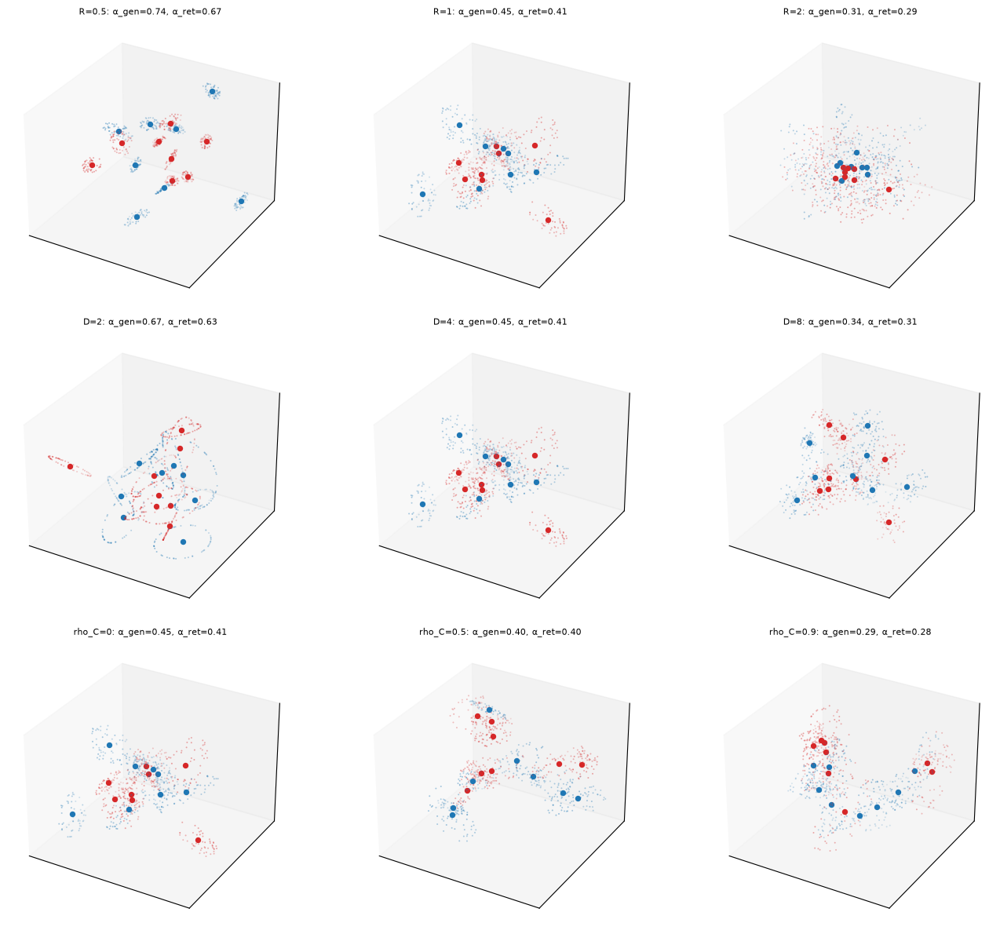

| knob | value | ensemble | α | Ψ_eff | R_eff | D_eff | utility | radius | dimension | residual |
|---|---|---|---|---|---|---|---|---|---|---|
| R | 0.5 | generic | 0.744 | 0.726 | 0.710 | 2.909 | -0.320 | +1.092 | -1.068 | 1.5e-16 |
| R | 0.5 | retained | 0.670 | 0.721 | 0.741 | 3.037 | -0.327 | +1.037 | -1.111 | 0.0e+00 |
| R | 1 | generic | 0.447 | 0.699 | 0.986 | 3.175 | -0.358 | +0.707 | -1.155 | 0.0e+00 |
| R | 1 | retained | 0.413 | 0.773 | 1.092 | 3.447 | -0.257 | +0.609 | -1.238 | 0.0e+00 |
| R | 2 | generic | 0.306 | 0.721 | 1.477 | 3.438 | -0.327 | +0.377 | -1.235 | 1.8e-16 |
| R | 2 | retained | 0.289 | 0.806 | 1.718 | 3.733 | -0.216 | +0.292 | -1.317 | 0.0e+00 |
| D | 2 | generic | 0.668 | 0.764 | 1.084 | 2.117 | -0.269 | +0.616 | -0.750 | 1.7e-16 |
| D | 2 | retained | 0.626 | 0.751 | 1.131 | 2.139 | -0.286 | +0.577 | -0.760 | 1.8e-16 |
| D | 4 | generic | 0.447 | 0.699 | 0.986 | 3.175 | -0.358 | +0.707 | -1.155 | 0.0e+00 |
| D | 4 | retained | 0.413 | 0.773 | 1.092 | 3.447 | -0.257 | +0.609 | -1.238 | 0.0e+00 |
| D | 8 | generic | 0.337 | 0.609 | 0.873 | 4.171 | -0.496 | +0.838 | -1.428 | 0.0e+00 |
| D | 8 | retained | 0.309 | 0.756 | 1.041 | 4.712 | -0.279 | +0.654 | -1.550 | 1.8e-16 |
| rho_C | 0 | generic | 0.447 | 0.699 | 0.986 | 3.175 | -0.358 | +0.707 | -1.155 | 0.0e+00 |
| rho_C | 0 | retained | 0.413 | 0.773 | 1.092 | 3.447 | -0.257 | +0.609 | -1.238 | 0.0e+00 |
| rho_C | 0.5 | generic | 0.399 | 0.708 | 1.105 | 3.224 | -0.346 | +0.598 | -1.171 | 1.4e-16 |
| rho_C | 0.5 | retained | 0.396 | 0.789 | 1.164 | 3.460 | -0.237 | +0.552 | -1.241 | 1.4e-16 |
| rho_C | 0.9 | generic | 0.287 | 0.717 | 1.607 | 3.469 | -0.333 | +0.327 | -1.244 | 1.9e-16 |
| rho_C | 0.9 | retained | 0.284 | 0.799 | 1.780 | 3.696 | -0.225 | +0.274 | -1.307 | 0.0e+00 |

In [5]:
from src.manifolds.generator import make_arrangement

N_T_DEMO = 8 if SMOKE else 200
VARIANTS = [("R", R, dict(R=R)) for R in (0.5, 1.0, 2.0)] + \
           [("D", D, dict(D=D)) for D in (2, 4, 8)] + \
           [("rho_C", r, dict(rho_C=r)) for r in (0.0, 0.5, 0.9)]
variant_res = []
fig = plt.figure(figsize=(14, 12))
for k, (knob, val, kw) in enumerate(VARIANTS):
    params = dict(R=cfg0.R, D=cfg0.D, rho_C=0.0) | kw
    arr = make_arrangement(cfg0.P, cfg0.d, params["D"], params["R"], cfg0.M,
                           np.random.default_rng(4242), rho_C=params["rho_C"])
    man = v.input_manifolds(arr.points)
    gen = v.manifold_geometry(man, None, n_t=N_T_DEMO, seed=11)
    ret = v.manifold_geometry(man, y0, n_t=N_T_DEMO, seed=12)
    variant_res.append((knob, val, gen, ret))
    ax = new_axes(fig, 3, 3, k + 1)
    b = v.pca_basis(arr.points.reshape(-1, cfg0.d), k=3)
    draw_task(ax, arr.points, arr.centers, y0, b,
              title=f"{knob}={val:g}: α_gen={gen['alpha']:.2f}, α_ret={ret['alpha']:.2f}")
plt.tight_layout(); plt.show()

rows = ["| knob | value | ensemble | α | Ψ_eff | R_eff | D_eff | utility | radius | dimension | residual |",
        "|---|---|---|---|---|---|---|---|---|---|---|"]
for knob, val, gen, ret in variant_res:
    for ens, g in (("generic", gen), ("retained", ret)):
        t3 = v.three_terms(g)
        rows.append(f"| {knob} | {val:g} | {ens} | {g['alpha']:.3f} | {g['Psi_eff']:.3f} | {g['R_eff']:.3f} | "
                    f"{g['D_eff']:.3f} | {t3['utility']:+.3f} | {t3['radius']:+.3f} | {t3['dimension']:+.3f} | "
                    f"{g['identity_residual']:.1e} |")
display(Markdown("\n".join(rows)))


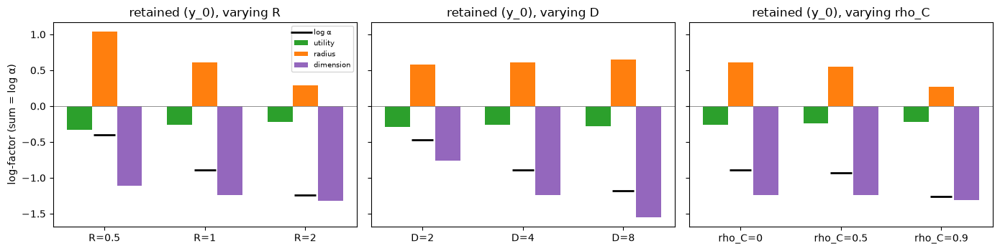

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, knob in zip(axes, ("R", "D", "rho_C")):
    sel = [(val, gen, ret) for k, val, gen, ret in variant_res if k == knob]
    x = np.arange(len(sel))
    for j, (term, col) in enumerate((("utility", "tab:green"), ("radius", "tab:orange"), ("dimension", "tab:purple"))):
        ax.bar(x + (j - 1) * 0.25, [v.three_terms(ret)[term] for _, _, ret in sel], width=0.25,
               color=col, label=term)
    ax.plot(x, [np.log(ret["alpha"]) for _, _, ret in sel], "k_", markersize=22, mew=2, label="log α")
    ax.set_xticks(x); ax.set_xticklabels([f"{knob}={val:g}" for val, _, _ in sel])
    ax.axhline(0, color="grey", lw=0.6)
    ax.set_title(f"retained (y_0), varying {knob}")
axes[0].set_ylabel("log-factor (sum = log α)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()


### 4.2 The same measurement on trained representations

The network sees inputs, but what this project measures is the **hidden representation**: the
same 16 task-0 clouds, pushed through module A. The next cell measures task 0's hidden clouds at
three points, using replicate 0 and the pinned `lr0`:
- at initialization, which is identical for every `γ`;
- after training task 0 at `γ = 0.03`;
- after training task 0 at `γ = 10`.

These are the values the trajectories in §6 start from.


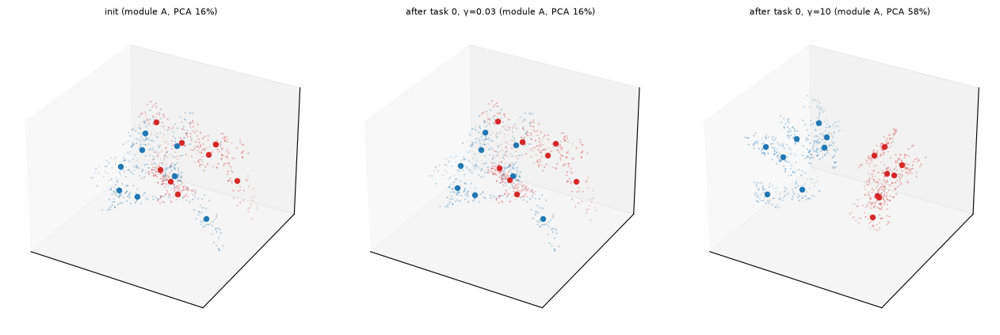

| representation | ensemble | α | Ψ_eff | R_eff | D_eff | utility | radius | dimension |
|---|---|---|---|---|---|---|---|---|
| init | generic | 0.332 | 0.599 | 0.881 | 4.136 | -0.512 | +0.828 | -1.420 |
| init | retained | 0.334 | 0.764 | 0.993 | 4.610 | -0.269 | +0.700 | -1.528 |
| after task 0, γ=0.03 | generic | 0.332 | 0.600 | 0.881 | 4.136 | -0.512 | +0.828 | -1.420 |
| after task 0, γ=0.03 | retained | 0.338 | 0.767 | 0.990 | 4.587 | -0.265 | +0.704 | -1.523 |
| after task 0, γ=10 | generic | 0.463 | 0.591 | 0.794 | 3.300 | -0.526 | +0.950 | -1.194 |
| after task 0, γ=10 | retained | 1.989 | 1.545 | 0.813 | 1.951 | +0.435 | +0.921 | -0.668 |

In [7]:
model_init = v.build_model(cfg, 1.0, 0)
trained = {"init": model_init}
for g in (0.03, 10.0):
    trained[f"after task 0, γ={g:g}"] = v.train_first_task(cfg, g, stream0, 0)
fig = plt.figure(figsize=(13, 4.2))
rows = ["| representation | ensemble | α | Ψ_eff | R_eff | D_eff | utility | radius | dimension |",
        "|---|---|---|---|---|---|---|---|---|"]
hidden_points = {}
for k, (name, m) in enumerate(trained.items()):
    H = np.stack([m.hidden(A0.points[i], "A") for i in range(cfg.P)])      # (P, M, N)
    hidden_points[name] = H
    ax = new_axes(fig, 1, 3, k + 1)
    b = v.pca_basis(H.reshape(-1, cfg.N), k=3)
    draw_task(ax, H, H.mean(axis=1), y0, b, title=f"{name} (module A, PCA {100*b[2][:PROJ_DIM].sum():.0f}%)")
    man = m.manifold_representation(A0.points, "A")
    for ens, yy, sd in (("generic", None, 21), ("retained", y0, 22)):
        g = v.manifold_geometry(man, yy, n_t=N_T_DEMO, seed=sd)
        t3 = v.three_terms(g)
        rows.append(f"| {name} | {ens} | {g['alpha']:.3f} | {g['Psi_eff']:.3f} | {g['R_eff']:.3f} | {g['D_eff']:.3f} | "
                    f"{t3['utility']:+.3f} | {t3['radius']:+.3f} | {t3['dimension']:+.3f} |")
plt.tight_layout(); plt.show()
display(Markdown("\n".join(rows)))


## 5. The grid: all cells × all `γ` × replicates

Each arm trains one stream for all 16 tasks. Task 0 is measured at initialization and after
every task boundary, which gives lags 0 to 15. The lag is the number of tasks trained since task
0, and boundary 0 is lag 0.
- **Behaviour** is measured on fresh points re-sampled once from task 0's clouds, the same
  points at every boundary:
  - sign accuracy;
  - mean margin `y · f`;
  - 5th-percentile margin.
- **Geometry** is measured on task 0's training points in module A: retained (`y_0`) and generic
  GLUE. Each uses one measurement seed reused at every boundary, so a change between boundaries
  is a change in the representation, not in the estimator's random draws.
- **Manipulation check:** `‖ΔW‖/‖W‖` for both modules at every boundary.

A replicate `r` uses stream `30100 + r` and init seed `r`. Initialization is paired across `γ`
and cells, and the stream is paired across `γ`. An arm in which any task fails to reach
`target_loss` is marked unusable and **excluded from every figure**; all such arms are listed.

The first execution uses `N_REPS = 3`. Raising it later reuses every finished arm from the
cache and runs only the new replicates.


In [15]:
N_REPS = 2 if SMOKE else 3       # first execution: 3; extend later, the cache keeps finished arms
specs = [v.ArmSpec(g, s_f, h, r) for r in range(N_REPS) for (s_f, h) in CELLS for g in v.GAMMAS]
t0 = time.time()
arms = v.run_grid(cfg, specs, workers=WORKERS, checkpoint=str(CACHE / "grid.jsonl"))
print(f"{len(arms)} arms; wall time this run {time.time() - t0:.0f} s; "
      f"summed arm time {sum(a['wall_seconds'] for a in arms) / 3600:.1f} h")
bad = v.unusable(arms)
print(f"unusable arms (excluded): {len(bad)}")
for s in bad:
    print("  ", s)


270 arms; wall time this run 13326 s; summed arm time 282.8 h
unusable arms (excluded): 0


In [16]:
X_BOUNDARY = np.arange(-1, cfg.T)            # -1 = initialization


def grid_figure(getter, ylabel, title, *, delta=False, band=None, logy=False, x0=None):
    # One panel per (s_f, Hamming); one line per γ; mean ± 95% CI over usable replicates.
    # `delta`: subtract each replicate's value at boundary 0 (lag 0) and plot lags 0..15.
    fig, axes = plt.subplots(3, 5, figsize=(18, 9), sharex=True, sharey=True)
    for i, s_f in enumerate(v.S_F_LEVELS):
        for j, h in enumerate(v.HAMMING_LEVELS):
            ax = axes[i, j]
            ns = []
            for g in v.GAMMAS:
                Y = v.trajectory(arms, s_f, h, g, getter)
                if Y.size == 0:
                    continue
                x = X_BOUNDARY
                if delta:
                    Y = Y[:, 1:] - Y[:, [1]]
                    x = X_BOUNDARY[1:]
                mean, half, n = v.ci(Y)
                ns.append(n)
                ax.plot(x, mean, color=GAMMA_COLORS[g], lw=1.4, label=f"γ={g:g}")
                if n >= 2:
                    ax.fill_between(x, mean - half, mean + half, color=GAMMA_COLORS[g], alpha=0.18, lw=0)
            if band is not None:
                ax.axhspan(-band, band, color="grey", alpha=0.25, lw=0)
            if logy:
                ax.set_yscale("log")
            ax.set_title(f"{v.cell_label(s_f, h)}  (n={min(ns) if ns else 0}–{max(ns) if ns else 0})", fontsize=8)
            if i == 2:
                ax.set_xlabel("lag (tasks since task 0)" if delta else "boundary (−1 = init)")
            if j == 0:
                ax.set_ylabel(ylabel)
    axes[0, 0].legend(fontsize=7, ncol=2)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(); plt.show()


## 6. Behaviour on task 0, per condition

Sign accuracy on task 0 can sit at 1.0 while the margin underneath it moves, so a flat accuracy
curve does not by itself mean nothing changed. The margins are the graded quantities. Shaded
bands are 95% CIs over replicates.


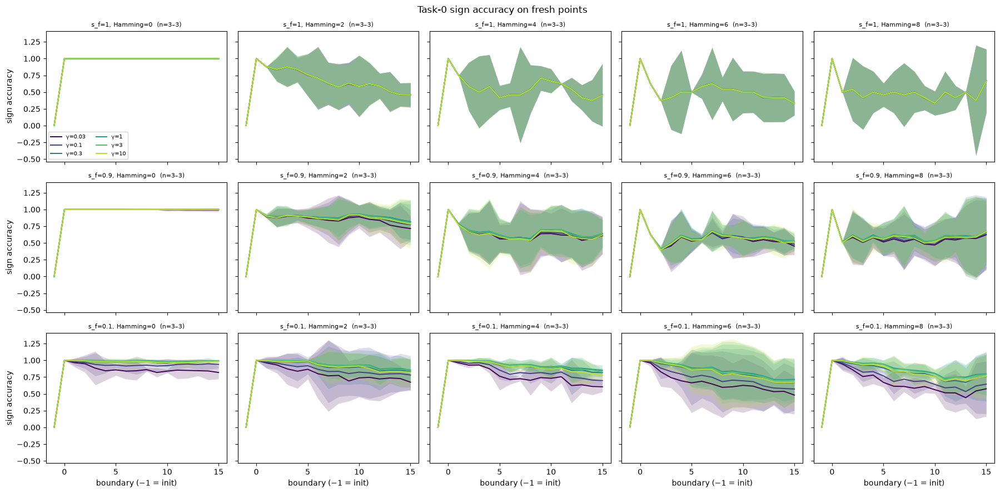

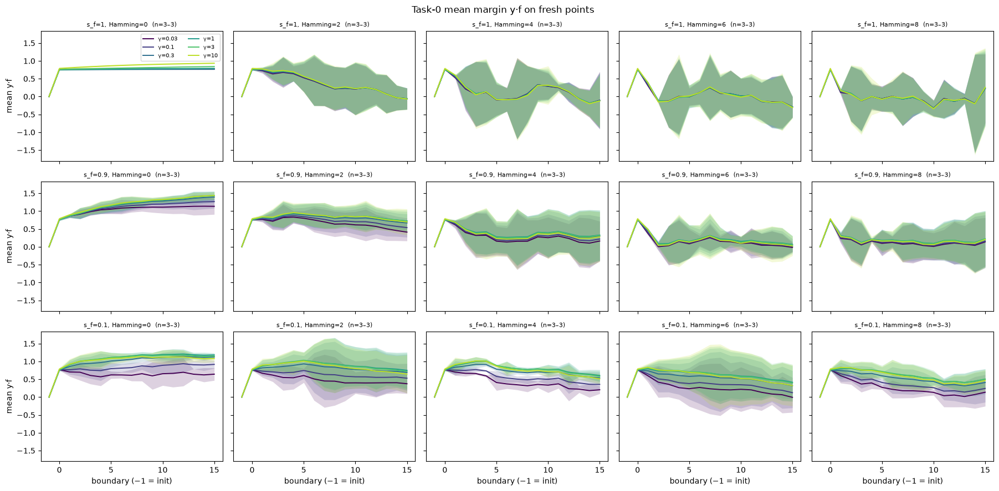

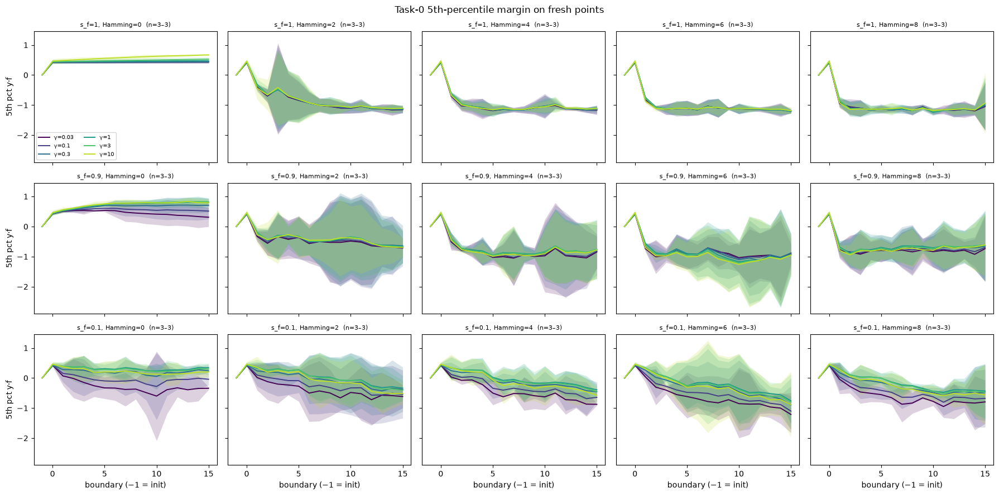

In [17]:
grid_figure(lambda r: r["sign_accuracy"], "sign accuracy", "Task-0 sign accuracy on fresh points")
grid_figure(lambda r: r["margin_mean"], "mean y·f", "Task-0 mean margin y·f on fresh points")
grid_figure(lambda r: r["margin_p05"], "5th pct y·f", "Task-0 5th-percentile margin on fresh points")


**Training cost and the manipulation check.** The first plot is the number of steps each task
needed to reach `target_loss`; its x-axis is the task index. The second is the relative
hidden-weight change `‖W − W(0)‖/‖W(0)‖` of module A, on a log axis. If the `γ` lines did not
separate in weight change, `γ` would not be doing what it is meant to.


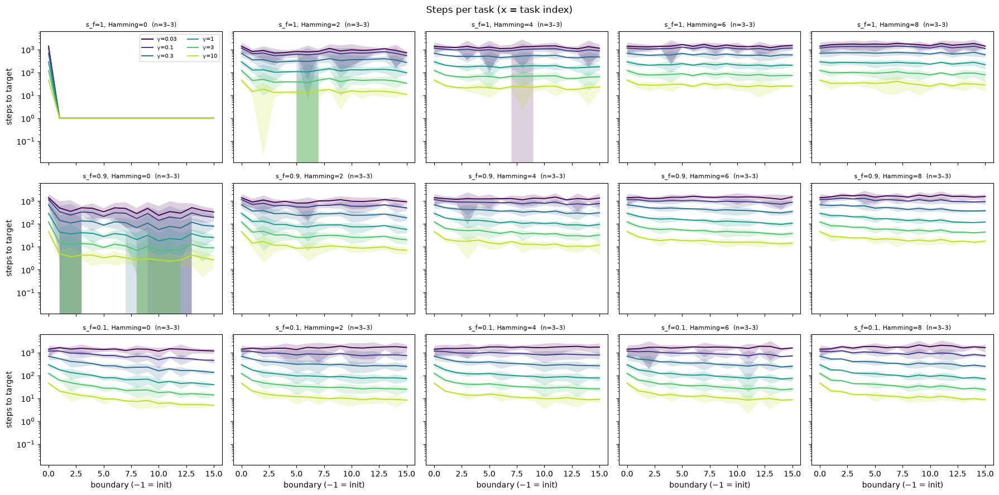

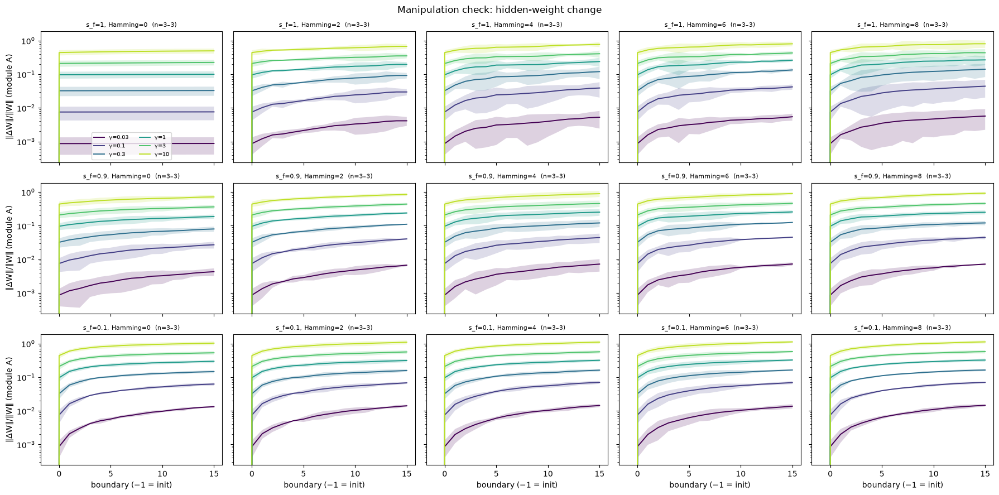

In [18]:
grid_figure(lambda r: r.get("steps", np.nan), "steps to target", "Steps per task (x = task index)", logy=True)
grid_figure(lambda r: r["weight_change"]["A"], "‖ΔW‖/‖W‖ (module A)", "Manipulation check: hidden-weight change", logy=True)


## 7. Geometry of task 0, per condition

### 7.1 Noise floor, measured on this configuration

The floor of a quantity is its standard deviation over 12 measurement seeds on one **fixed**
representation: task 0's hidden clouds after task 0 is trained, replicate 0, at each `γ`. The
grey band in the change plots is ±2× the largest floor over `γ`. A change inside the band is not
resolved.


In [19]:
floors = {}
for g in v.GAMMAS:
    m = v.train_first_task(cfg, g, stream0, 0)
    man = m.manifold_representation(A0.points, "A")
    K_FLOOR = 3 if SMOKE else 12
    floors[g] = {"retained": v.noise_floor(cfg, man, y0, K=K_FLOOR, workers=WORKERS),
                 "generic": v.noise_floor(cfg, man, None, K=K_FLOOR, workers=WORKERS)}
keys = ["log_alpha", "utility", "radius", "dimension", "rho_c_glue", "rho_c_signed"]
rows = ["| γ | ensemble | " + " | ".join(keys) + " |", "|---|---|" + "---|" * len(keys)]
for g in v.GAMMAS:
    for ens in ("retained", "generic"):
        rows.append(f"| {g:g} | {ens} | " + " | ".join(f"{floors[g][ens][k]:.4f}" for k in keys) + " |")
display(Markdown("\n".join(rows)))
FLOOR = {ens: {k: max(floors[g][ens][k] for g in v.GAMMAS) for k in keys} for ens in ("retained", "generic")}


| γ | ensemble | log_alpha | utility | radius | dimension | rho_c_glue | rho_c_signed |
|---|---|---|---|---|---|---|---|
| 0.03 | retained | 0.0328 | 0.0222 | 0.0116 | 0.0249 | 0.0074 | 0.0018 |
| 0.03 | generic | 0.0440 | 0.0343 | 0.0132 | 0.0313 | 0.0069 | 0.0011 |
| 0.1 | retained | 0.0346 | 0.0215 | 0.0101 | 0.0258 | 0.0079 | 0.0018 |
| 0.1 | generic | 0.0440 | 0.0359 | 0.0138 | 0.0316 | 0.0062 | 0.0011 |
| 0.3 | retained | 0.0396 | 0.0279 | 0.0162 | 0.0286 | 0.0133 | 0.0021 |
| 0.3 | generic | 0.0439 | 0.0369 | 0.0148 | 0.0338 | 0.0086 | 0.0012 |
| 1 | retained | 0.0480 | 0.0311 | 0.0242 | 0.0352 | 0.0189 | 0.0024 |
| 1 | generic | 0.0443 | 0.0461 | 0.0175 | 0.0325 | 0.0109 | 0.0015 |
| 3 | retained | 0.0587 | 0.0347 | 0.0170 | 0.0417 | 0.0141 | 0.0025 |
| 3 | generic | 0.0452 | 0.0524 | 0.0232 | 0.0327 | 0.0201 | 0.0017 |
| 10 | retained | 0.0766 | 0.0467 | 0.0279 | 0.0469 | 0.0175 | 0.0023 |
| 10 | generic | 0.0474 | 0.0589 | 0.0203 | 0.0322 | 0.0540 | 0.0013 |

### 7.2 Capacity of task 0 over the stream

Retained capacity measures task 0's own labels; generic capacity averages over random balanced
labels. Both are measured on the same clouds at every boundary.


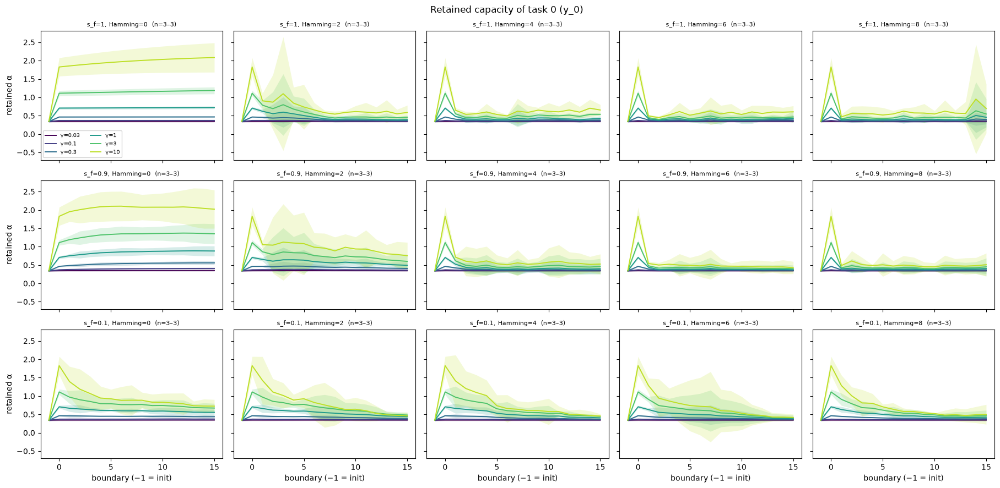

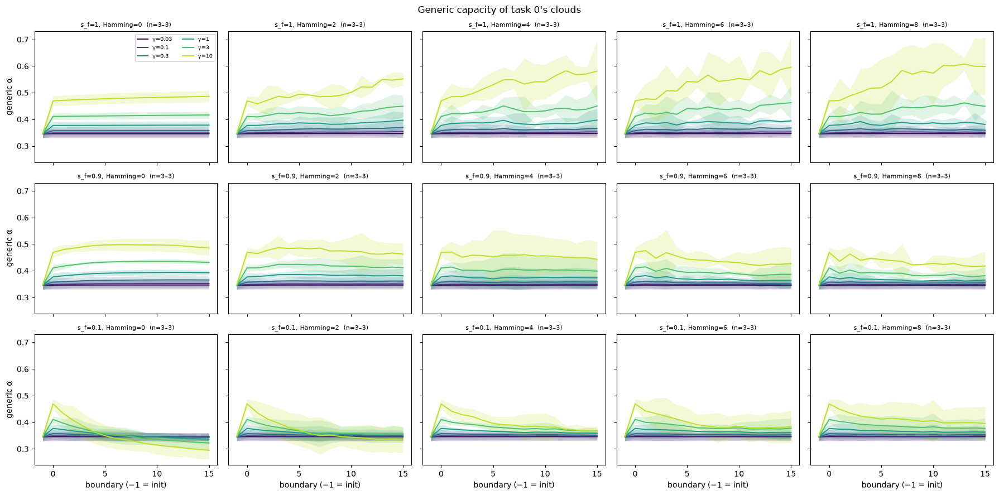

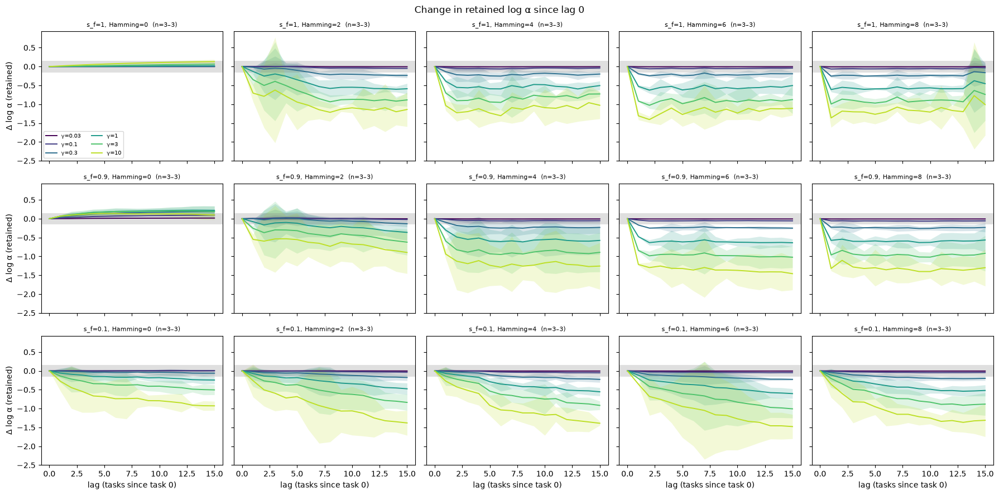

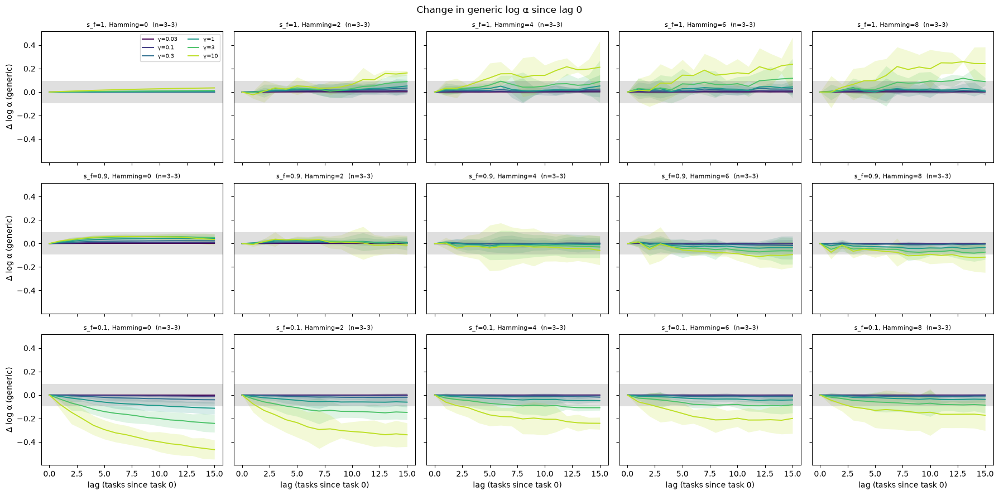

In [20]:
grid_figure(lambda r: r["retained"]["alpha"], "retained α", "Retained capacity of task 0 (y_0)")
grid_figure(lambda r: r["generic"]["alpha"], "generic α", "Generic capacity of task 0's clouds")
grid_figure(lambda r: np.log(r["retained"]["alpha"]), "Δ log α (retained)",
            "Change in retained log α since lag 0", delta=True, band=2 * FLOOR["retained"]["log_alpha"])
grid_figure(lambda r: np.log(r["generic"]["alpha"]), "Δ log α (generic)",
            "Change in generic log α since lag 0", delta=True, band=2 * FLOOR["generic"]["log_alpha"])


### 7.3 The three terms of the retained change

Each figure shows one term of `Δ log α = Δ utility + Δ radius + Δ dimension`, relative to lag 0,
per condition and `γ`. The three are on the same y-scale, so their sizes can be compared
directly. Shares are deliberately not shown: a share is uninterpretable when the total, or any
term, sits inside the floor.


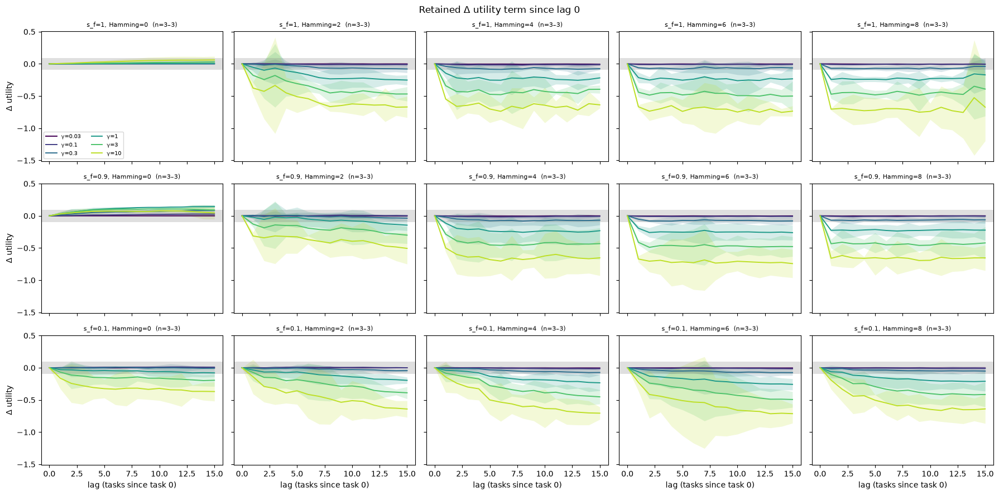

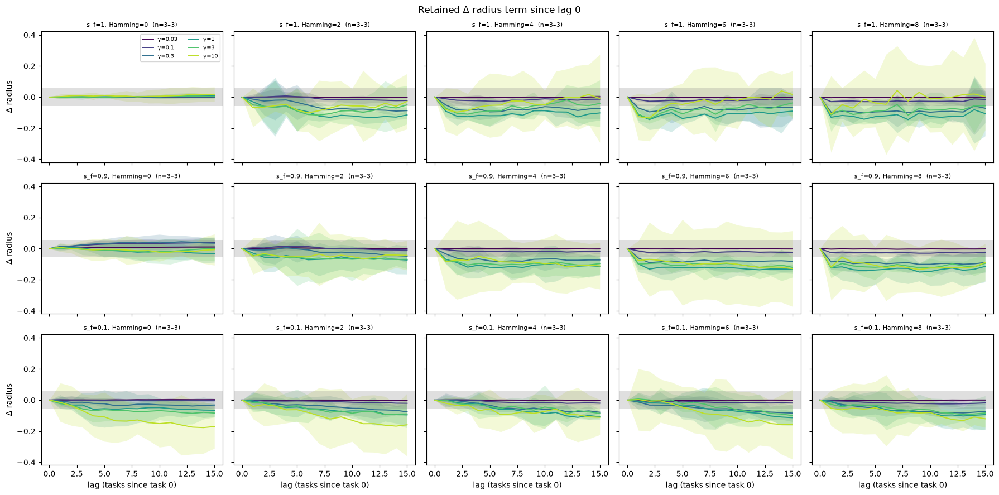

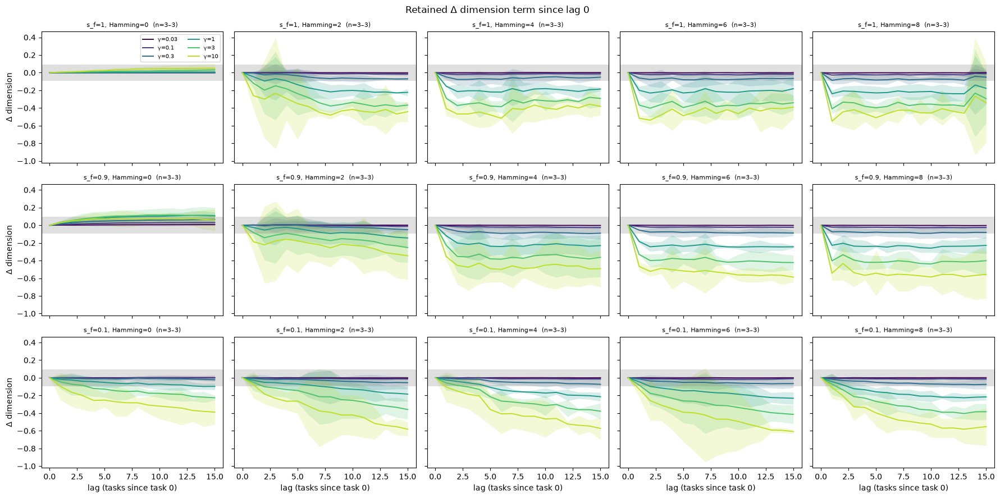

In [21]:
for term in ("utility", "radius", "dimension"):
    grid_figure(lambda r, t=term: v.three_terms(r["retained"])[t], f"Δ {term}",
                f"Retained Δ {term} term since lag 0", delta=True, band=2 * FLOOR["retained"][term])


### 7.4 Centre correlation of task 0's clouds

Two conventions are reported, and both are always shown. Their numbers are not comparable with
each other:
- `rho_c_glue`: absolute value, unnormalized.
- `rho_c_signed`: signed and normalized.


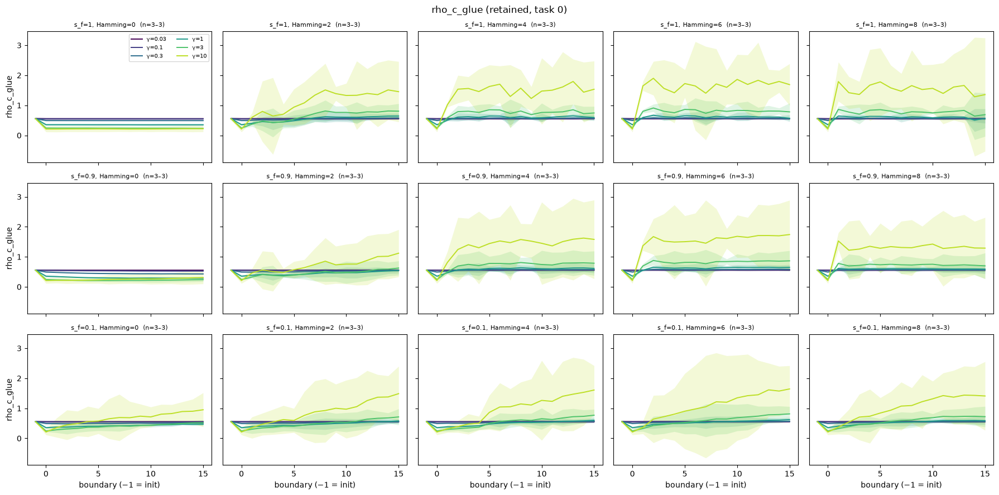

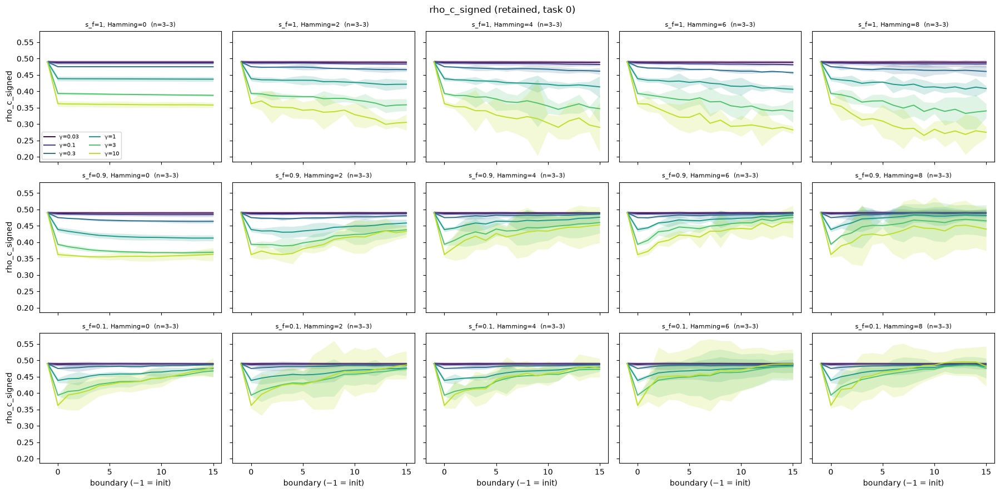

In [22]:
grid_figure(lambda r: r["retained"]["rho_c_glue"], "rho_c_glue", "rho_c_glue (retained, task 0)")
grid_figure(lambda r: r["retained"]["rho_c_signed"], "rho_c_signed", "rho_c_signed (retained, task 0)")


## 8. Where the trained representations sit relative to the generator variants

Each marker is one (condition, `γ`): the replicate mean of retained `(R_eff, D_eff)` and
`(Ψ_eff, α)`, at lag 0 (circles) and lag 15 (triangles), coloured by `γ`. Grey crosses are the
input-space variants from §4.1. Each marker is a single condition; nothing is pooled. With 90
markers per lag, read the figure for the range covered, not for individual conditions.


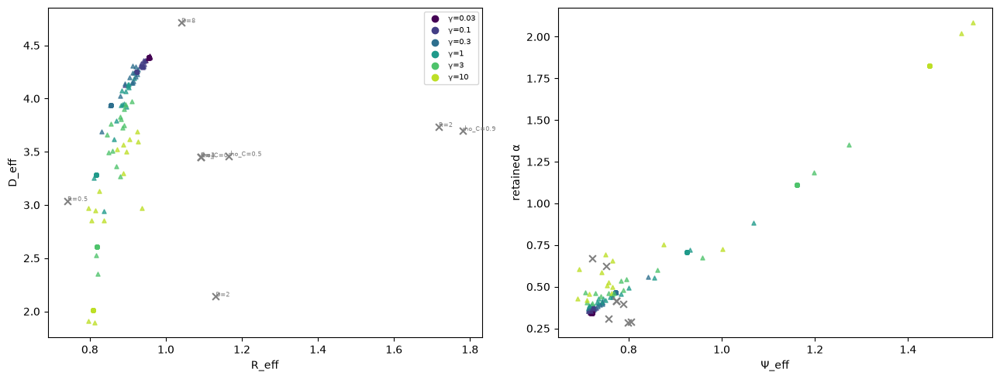

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for (s_f, h) in CELLS:
    for g in v.GAMMAS:
        for col, mk in ((1, "o"), (cfg.T, "^")):
            R = v.trajectory(arms, s_f, h, g, lambda r: r["retained"]["R_eff"])
            if R.size == 0:
                continue
            D = v.trajectory(arms, s_f, h, g, lambda r: r["retained"]["D_eff"])
            Ps = v.trajectory(arms, s_f, h, g, lambda r: r["retained"]["Psi_eff"])
            al = v.trajectory(arms, s_f, h, g, lambda r: r["retained"]["alpha"])
            axes[0].scatter(R[:, col].mean(), D[:, col].mean(), color=GAMMA_COLORS[g], marker=mk, s=14, alpha=0.7)
            axes[1].scatter(Ps[:, col].mean(), al[:, col].mean(), color=GAMMA_COLORS[g], marker=mk, s=14, alpha=0.7)
for knob, val, gen, ret in variant_res:
    axes[0].scatter(ret["R_eff"], ret["D_eff"], color="grey", marker="x", s=40)
    axes[0].annotate(f"{knob}={val:g}", (ret["R_eff"], ret["D_eff"]), fontsize=6, color="grey")
    axes[1].scatter(ret["Psi_eff"], ret["alpha"], color="grey", marker="x", s=40)
axes[0].set_xlabel("R_eff"); axes[0].set_ylabel("D_eff")
axes[1].set_xlabel("Ψ_eff"); axes[1].set_ylabel("retained α")
for g in v.GAMMAS:
    axes[0].scatter([], [], color=GAMMA_COLORS[g], label=f"γ={g:g}")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()


## 9. Coverage and observations

The table lists, per condition and `γ`, the change in retained `log α` from lag 0 to lag 15.
Each entry is the mean, its 95% CI, and the usable replicate count. An entry is marked **R**
(resolved) only if the CI excludes 0 *and* `|mean| ≥ 2 ×` floor. The table is a record, not a
reading.


In [24]:
fl = 2 * FLOOR["retained"]["log_alpha"]
rows = ["| s_f | Hamming | " + " | ".join(f"γ={g:g}" for g in v.GAMMAS) + " |", "|---|---|" + "---|" * len(v.GAMMAS)]
for s_f, h in CELLS:
    cells_txt = []
    for g in v.GAMMAS:
        Y = v.trajectory(arms, s_f, h, g, lambda r: np.log(r["retained"]["alpha"]))
        if Y.size == 0:
            cells_txt.append("—"); continue
        d = Y[:, cfg.T] - Y[:, 1]
        mean, half, n = v.ci(d)
        res = (n >= 2 and abs(mean) - half > 0 and abs(mean) >= fl)
        cells_txt.append(f"{mean:+.3f} ±{half:.3f} (n={n}){' **R**' if res else ''}")
    rows.append(f"| {s_f:g} | {h} | " + " | ".join(cells_txt) + " |")
display(Markdown("\n".join(rows)))
print(f"2 × floor(log α, retained) = {fl:.4f}")


| s_f | Hamming | γ=0.03 | γ=0.1 | γ=0.3 | γ=1 | γ=3 | γ=10 |
|---|---|---|---|---|---|---|---|
| 1 | 0 | +0.000 ±0.000 (n=3) | +0.001 ±0.000 (n=3) | +0.005 ±0.001 (n=3) | +0.021 ±0.002 (n=3) | +0.065 ±0.013 (n=3) | +0.131 ±0.057 (n=3) |
| 1 | 2 | -0.005 ±0.001 (n=3) | -0.049 ±0.013 (n=3) | -0.236 ±0.066 (n=3) **R** | -0.589 ±0.140 (n=3) **R** | -0.885 ±0.174 (n=3) **R** | -1.139 ±0.454 (n=3) **R** |
| 1 | 4 | -0.003 ±0.005 (n=3) | -0.037 ±0.030 (n=3) | -0.199 ±0.080 (n=3) **R** | -0.505 ±0.121 (n=3) **R** | -0.728 ±0.065 (n=3) **R** | -1.028 ±0.359 (n=3) **R** |
| 1 | 6 | -0.004 ±0.002 (n=3) | -0.039 ±0.015 (n=3) | -0.192 ±0.052 (n=3) **R** | -0.504 ±0.271 (n=3) **R** | -0.878 ±0.370 (n=3) **R** | -1.108 ±0.187 (n=3) **R** |
| 1 | 8 | -0.003 ±0.011 (n=3) | -0.033 ±0.086 (n=3) | -0.163 ±0.282 (n=3) | -0.454 ±0.533 (n=3) | -0.740 ±0.692 (n=3) **R** | -1.010 ±0.815 (n=3) **R** |
| 0.9 | 0 | +0.017 ±0.003 (n=3) | +0.095 ±0.022 (n=3) | +0.186 ±0.064 (n=3) **R** | +0.221 ±0.113 (n=3) **R** | +0.192 ±0.143 (n=3) **R** | +0.098 ±0.125 (n=3) |
| 0.9 | 2 | -0.001 ±0.003 (n=3) | -0.022 ±0.021 (n=3) | -0.135 ±0.083 (n=3) | -0.363 ±0.213 (n=3) **R** | -0.622 ±0.345 (n=3) **R** | -0.896 ±0.560 (n=3) **R** |
| 0.9 | 4 | -0.005 ±0.005 (n=3) | -0.052 ±0.041 (n=3) | -0.232 ±0.157 (n=3) **R** | -0.576 ±0.367 (n=3) **R** | -0.892 ±0.520 (n=3) **R** | -1.256 ±0.618 (n=3) **R** |
| 0.9 | 6 | -0.006 ±0.001 (n=3) | -0.056 ±0.011 (n=3) | -0.250 ±0.024 (n=3) **R** | -0.638 ±0.102 (n=3) **R** | -1.021 ±0.279 (n=3) **R** | -1.458 ±0.433 (n=3) **R** |
| 0.9 | 8 | -0.006 ±0.006 (n=3) | -0.055 ±0.037 (n=3) | -0.232 ±0.121 (n=3) **R** | -0.565 ±0.319 (n=3) **R** | -0.918 ±0.473 (n=3) **R** | -1.299 ±0.489 (n=3) **R** |
| 0.1 | 0 | +0.005 ±0.004 (n=3) | +0.007 ±0.017 (n=3) | -0.061 ±0.058 (n=3) | -0.243 ±0.101 (n=3) **R** | -0.504 ±0.130 (n=3) **R** | -0.928 ±0.120 (n=3) **R** |
| 0.1 | 2 | -0.002 ±0.006 (n=3) | -0.033 ±0.035 (n=3) | -0.175 ±0.084 (n=3) **R** | -0.475 ±0.154 (n=3) **R** | -0.837 ±0.216 (n=3) **R** | -1.381 ±0.330 (n=3) **R** |
| 0.1 | 4 | -0.004 ±0.004 (n=3) | -0.048 ±0.031 (n=3) | -0.226 ±0.080 (n=3) **R** | -0.555 ±0.110 (n=3) **R** | -0.916 ±0.115 (n=3) **R** | -1.390 ±0.055 (n=3) **R** |
| 0.1 | 6 | -0.004 ±0.004 (n=3) | -0.044 ±0.019 (n=3) | -0.225 ±0.020 (n=3) **R** | -0.603 ±0.129 (n=3) **R** | -1.007 ±0.244 (n=3) **R** | -1.478 ±0.322 (n=3) **R** |
| 0.1 | 8 | -0.003 ±0.004 (n=3) | -0.040 ±0.025 (n=3) | -0.198 ±0.058 (n=3) **R** | -0.520 ±0.148 (n=3) **R** | -0.882 ±0.301 (n=3) **R** | -1.312 ±0.435 (n=3) **R** |

2 × floor(log α, retained) = 0.1531


### What this notebook does and does not test

| axis | varied here | status |
|---|---|---|
| consecutive feature similarity `s_f` | {1, 0.9, 0.1} | yes |
| consecutive rule change (Hamming) | {0, 2, 4, 6, 8} | yes |
| richness `γ` | six registered values | yes |
| task order | generated order only | **no** — separate notebook |
| similarity to non-consecutive tasks | not controlled; measured in §2 | covariate only |
| scale (`M`, `n_t`, `N`, `P`) | one reduced setting | **no** — scale ablations later |
| learning rate | one pin from the decade ladder | **no** — a sweep over final results is planned |
| initial alignment `a` | 0 only | **no** |
| learner (loss, optimizer) | MSE + full-batch GD only | **no** |
| architecture | one hidden layer, two modules | **no** |

### Provenance of the retained / generic distinction

- **Verified** from the repository's own reference record, `docs/03-references.md` §E.6. This is
  not a reading of the primary papers:
  - Generic capacity, averaged over random dichotomies, is the standard definition used by
    Chung et al. and by GLUE.
  - Capacity under a fixed or label-biased dichotomy has precedent: Montanari et al. 2019, and
    Chou et al. App. A.1, as cited there.
- **Inferred, not verified:**
  - The name "retained capacity".
  - Applying a fixed-dichotomy ensemble to a *past* task while training continues on later tasks.
  - The claim that this has no precedent. No literature search has checked it.

  Until checked, describe it as "fixed-dichotomy capacity, an existing ensemble choice, applied
  to past tasks".
